# **Introducción**

Aplicaremos el algoritmo de **árboles de decisión** al conjunto de datos *Fitness_Classification.csv* (2000 personas) para construir un modelo que prediga si una persona está **en forma** (`is_fit = 1`) o **no en forma** (`is_fit = 0`).

Atributos del conjunto de datos:
*   age: edad en años
*   height_cm: altura en centímetros
*   weight_kg: peso en kilogramos (contiene valores atípicos)
*   heart_rate: frecuencia cardíaca en reposo (latidos por minuto)
*   blood_pressure: presión arterial sistólica (mmHg)
*   sleep_hours: promedio de horas de sueño al día (contiene NaN)
*   nutrition_quality: calidad nutricional diaria, de 0 a 10
*   activity_index: nivel de actividad física, de 1 a 5
*   smokes: tabaquismo (tipos mixtos: 0, 1, "yes", "no")
*   gender: sexo, 'M' o 'F'
*   **is_fit (variable objetivo)**: 1 si está en forma, 0 en caso contrario

# Cargar librerías y datos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%pip install seaborn
import seaborn as sns

In [2]:
df = pd.read_csv('Fitness_Classification.csv', encoding = 'latin-1')
df

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65,69.6,117.0,NaN,2.37,3.97,no,F,1
1,69,186,95,60.8,114.8,7.5,8.77,3.19,0,F,1
2,46,192,103,61.4,116.4,NaN,8.20,2.03,0,F,0
3,32,189,83,60.2,130.1,7.0,6.18,3.68,0,M,1
4,60,175,99,58.1,115.8,8.0,9.95,4.83,yes,F,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98,60.7,106.1,NaN,1.54,3.25,1,M,1
1996,61,186,74,51.4,123.8,9.4,8.63,3.15,no,M,1
1997,77,198,89,76.7,103.6,8.3,1.98,3.36,yes,M,0
1998,62,190,63,80.7,115.9,6.7,9.21,2.39,1,F,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                2000 non-null   int64  
 1   height_cm          2000 non-null   int64  
 2   weight_kg          2000 non-null   int64  
 3   heart_rate         2000 non-null   float64
 4   blood_pressure     2000 non-null   float64
 5   sleep_hours        1840 non-null   float64
 6   nutrition_quality  2000 non-null   float64
 7   activity_index     2000 non-null   float64
 8   smokes             2000 non-null   str    
 9   gender             2000 non-null   str    
 10  is_fit             2000 non-null   int64  
dtypes: float64(5), int64(4), str(2)
memory usage: 156.3 KB


In [4]:
df.describe()

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,is_fit
count,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000,1840.000000,2000.000000,2000.000000,2000.000000
mean,49.114000,174.53300,83.540500,70.288600,119.908850,7.513315,5.035140,2.999040,0.399500
std,17.926564,14.37175,25.852534,11.846339,14.578032,1.502031,2.864156,1.136383,0.489918
min,18.000000,150.00000,30.000000,45.000000,90.000000,4.000000,0.000000,1.000000,0.000000
25%,34.000000,162.00000,64.000000,62.100000,109.700000,6.500000,2.547500,2.037500,0.000000
50%,49.000000,174.00000,83.000000,70.250000,120.000000,7.500000,5.065000,2.980000,0.000000
75%,65.000000,187.00000,102.000000,78.425000,129.800000,8.600000,7.470000,3.950000,1.000000
max,79.000000,199.00000,250.000000,118.600000,171.200000,12.000000,10.000000,4.990000,1.000000


# Limpieza de datos

## Valores atípicos (outliers)

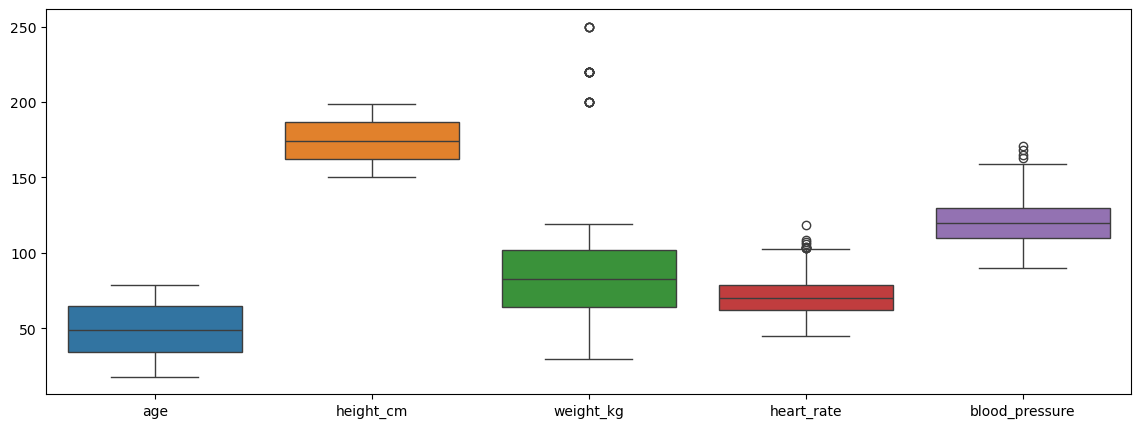

In [5]:
plt.figure(figsize=(14, 5))
sns.boxplot(data=df[['age', 'height_cm', 'weight_kg', 'heart_rate', 'blood_pressure']])
plt.show()

In [6]:
# Regla del rango intercuartílico (IQR) para el peso
Q1, Q3 = df['weight_kg'].quantile([0.25, 0.75])
limite_sup = Q3 + 1.5 * (Q3 - Q1)
print(f"Límite superior: {limite_sup}")
print("Pesos atípicos:", (df['weight_kg'] > limite_sup).sum())
df[df['weight_kg'] > limite_sup]['weight_kg'].value_counts()

Límite superior: 159.0
Pesos atípicos: 21


weight_kg
220    10
200     7
250     4
Name: count, dtype: int64

In [7]:
# Convertimos los pesos atípicos en valores vacíos para que el KNNImputer los reemplace
df.loc[df['weight_kg'] > limite_sup, 'weight_kg'] = np.nan
df.isnull().sum(axis=0)

age                    0
height_cm              0
weight_kg             21
heart_rate             0
blood_pressure         0
sleep_hours          160
nutrition_quality      0
activity_index         0
smokes                 0
gender                 0
is_fit                 0
dtype: int64

In [8]:
# Reemplzar 'F':0, 'M':1, y 'smokes': { 'no':0, 'yes':1}
df.gender.unique()
df.smokes.unique()

<StringArray>
['no', '0', 'yes', '1']
Length: 4, dtype: str

In [9]:
df.replace({'gender': {'F':0, 'M':1}, 'smokes': { 'no':0, 'yes':1}}, inplace = True)
df

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56,152,65.0,69.6,117.0,NaN,2.37,3.97,0,0,1
1,69,186,95.0,60.8,114.8,7.5,8.77,3.19,0,0,1
2,46,192,103.0,61.4,116.4,NaN,8.20,2.03,0,0,0
3,32,189,83.0,60.2,130.1,7.0,6.18,3.68,0,1,1
4,60,175,99.0,58.1,115.8,8.0,9.95,4.83,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
1995,52,173,98.0,60.7,106.1,NaN,1.54,3.25,1,1,1
1996,61,186,74.0,51.4,123.8,9.4,8.63,3.15,0,1,1
1997,77,198,89.0,76.7,103.6,8.3,1.98,3.36,1,1,0
1998,62,190,63.0,80.7,115.9,6.7,9.21,2.39,1,0,0


In [10]:
df.gender.unique()
df.smokes.unique()

array([0, '0', 1, '1'], dtype=object)

In [11]:
#Verificamos si existen registros vacíos
df.isnull().values.any()

np.True_

<Axes: >

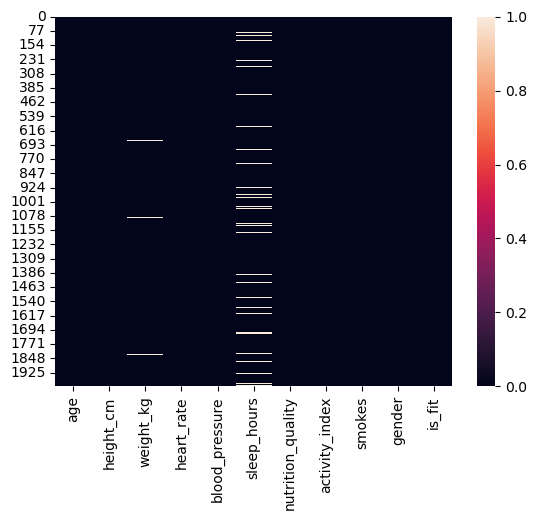

In [12]:
#Creamos un mapa de calor para identificar visualmente los atributos que tienen registros vacíos
sns.heatmap(df.isnull())

In [13]:
#Sumamos el número de registros vacíos en cada columna
df.isnull().sum(axis=0)

age                    0
height_cm              0
weight_kg             21
heart_rate             0
blood_pressure         0
sleep_hours          160
nutrition_quality      0
activity_index         0
smokes                 0
gender                 0
is_fit                 0
dtype: int64

In [14]:
#Reemplazamos los valores faltantes con ayuda del clasificador knn.
#Este método nos permite reemplazar los valores faltantes por valores muy parecidos a sus "vecinos"

from sklearn.impute import KNNImputer

impKNN = KNNImputer(n_neighbors=10)
impKNN.fit_transform(df)
fitness = impKNN.transform(df)
fitness = pd.DataFrame(fitness, columns=df.columns)
fitness

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender,is_fit
0,56.0,152.0,65.0,69.6,117.0,7.76,2.37,3.97,0.0,0.0,1.0
1,69.0,186.0,95.0,60.8,114.8,7.50,8.77,3.19,0.0,0.0,1.0
2,46.0,192.0,103.0,61.4,116.4,6.70,8.20,2.03,0.0,0.0,0.0
3,32.0,189.0,83.0,60.2,130.1,7.00,6.18,3.68,0.0,1.0,1.0
4,60.0,175.0,99.0,58.1,115.8,8.00,9.95,4.83,1.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
1995,52.0,173.0,98.0,60.7,106.1,7.76,1.54,3.25,1.0,1.0,1.0
1996,61.0,186.0,74.0,51.4,123.8,9.40,8.63,3.15,0.0,1.0,1.0
1997,77.0,198.0,89.0,76.7,103.6,8.30,1.98,3.36,1.0,1.0,0.0
1998,62.0,190.0,63.0,80.7,115.9,6.70,9.21,2.39,1.0,0.0,0.0


# Exportar csv

In [15]:
fitness.to_csv('fitness2.csv',index=False)

# Análisis exploratorio de los datos

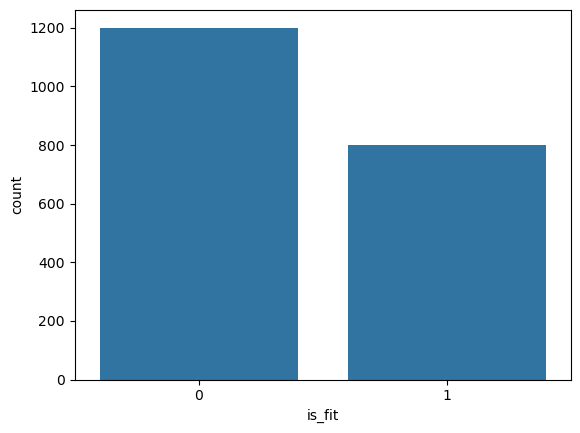

In [16]:
#Creamos un histograma para identificar el número de personas que estan en forma y no en forma
sns.countplot(x=df['is_fit'])
plt.show()

# Separación del conjunto en datos de entrenamiento y de prueba

In [17]:
from sklearn.model_selection import train_test_split
#split dataset in features and target variable
X = fitness.drop(columns='is_fit')
y = fitness['is_fit']
X

,age,height_cm,weight_kg,heart_rate,blood_pressure,sleep_hours,nutrition_quality,activity_index,smokes,gender
0,56.0,152.0,65.0,69.6,117.0,7.76,2.37,3.97,0.0,0.0
1,69.0,186.0,95.0,60.8,114.8,7.50,8.77,3.19,0.0,0.0
2,46.0,192.0,103.0,61.4,116.4,6.70,8.20,2.03,0.0,0.0
3,32.0,189.0,83.0,60.2,130.1,7.00,6.18,3.68,0.0,1.0
4,60.0,175.0,99.0,58.1,115.8,8.00,9.95,4.83,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...
1995,52.0,173.0,98.0,60.7,106.1,7.76,1.54,3.25,1.0,1.0
1996,61.0,186.0,74.0,51.4,123.8,9.40,8.63,3.15,0.0,1.0
1997,77.0,198.0,89.0,76.7,103.6,8.30,1.98,3.36,1.0,1.0
1998,62.0,190.0,63.0,80.7,115.9,6.70,9.21,2.39,1.0,0.0


In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, stratify=y, random_state=42)

# Modelo de predicción: Árboles de decisión

## Selección de los hiperparámetros del modelo

In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

param_dist = {"max_depth": range(2, 9),           # niveles del árbol
              "max_features": range(1, 11),       # atributos a considerar
              "min_samples_leaf": [10, 25, 50],   # mínimo de muestras en cada hoja
              "criterion": ["gini", "entropy"]}   # criterio para dividir

grid_search = GridSearchCV(estimator=DecisionTreeClassifier(random_state=42),
                           param_grid=param_dist, cv=5)
grid_search.fit(X_train, y_train)
grid_search.best_params_

{'criterion': 'entropy',
 'max_depth': 5,
 'max_features': 9,
 'min_samples_leaf': 25}

In [20]:
grid_search.best_score_

np.float64(0.7350746268656716)

## Modelo

In [21]:
from sklearn.tree import DecisionTreeClassifier
# https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

dtree = DecisionTreeClassifier(criterion= 'gini', max_depth= 5, max_features= 9,  min_samples_leaf= 25, random_state=67)
dtree

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",25
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",67
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node

In [22]:
dtree.fit(X_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",25
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",9
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",67
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node

In [23]:
dtree.score(X_train, y_train)

0.7820895522388059

## Predicción y evaluación

In [24]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

predictions = dtree.predict(X_test)
print(f"Exactitud: {accuracy_score(y_test, predictions):.2f}")
print(f"Valor F1: {f1_score(y_test, predictions):.2f}")
print(classification_report(y_test, predictions, target_names=['No en forma', 'En forma']))

Exactitud: 0.73
Valor F1: 0.64
              precision    recall  f1-score   support

 No en forma       0.75      0.82      0.79       396
    En forma       0.69      0.60      0.64       264

    accuracy                           0.73       660
   macro avg       0.72      0.71      0.71       660
weighted avg       0.73      0.73      0.73       660



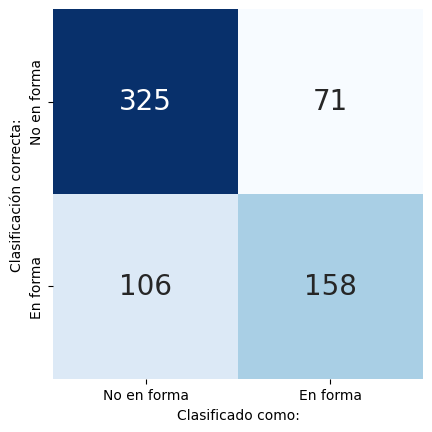

In [25]:
mat_dt = confusion_matrix(y_test, predictions)
labels = ['No en forma', 'En forma']

sns.heatmap(mat_dt, square=True, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=labels, yticklabels=labels, annot_kws={"size": 20})
plt.xlabel('Clasificado como:')
plt.ylabel('Clasificación correcta:')
plt.show()

## Visualización del árbol obtenido

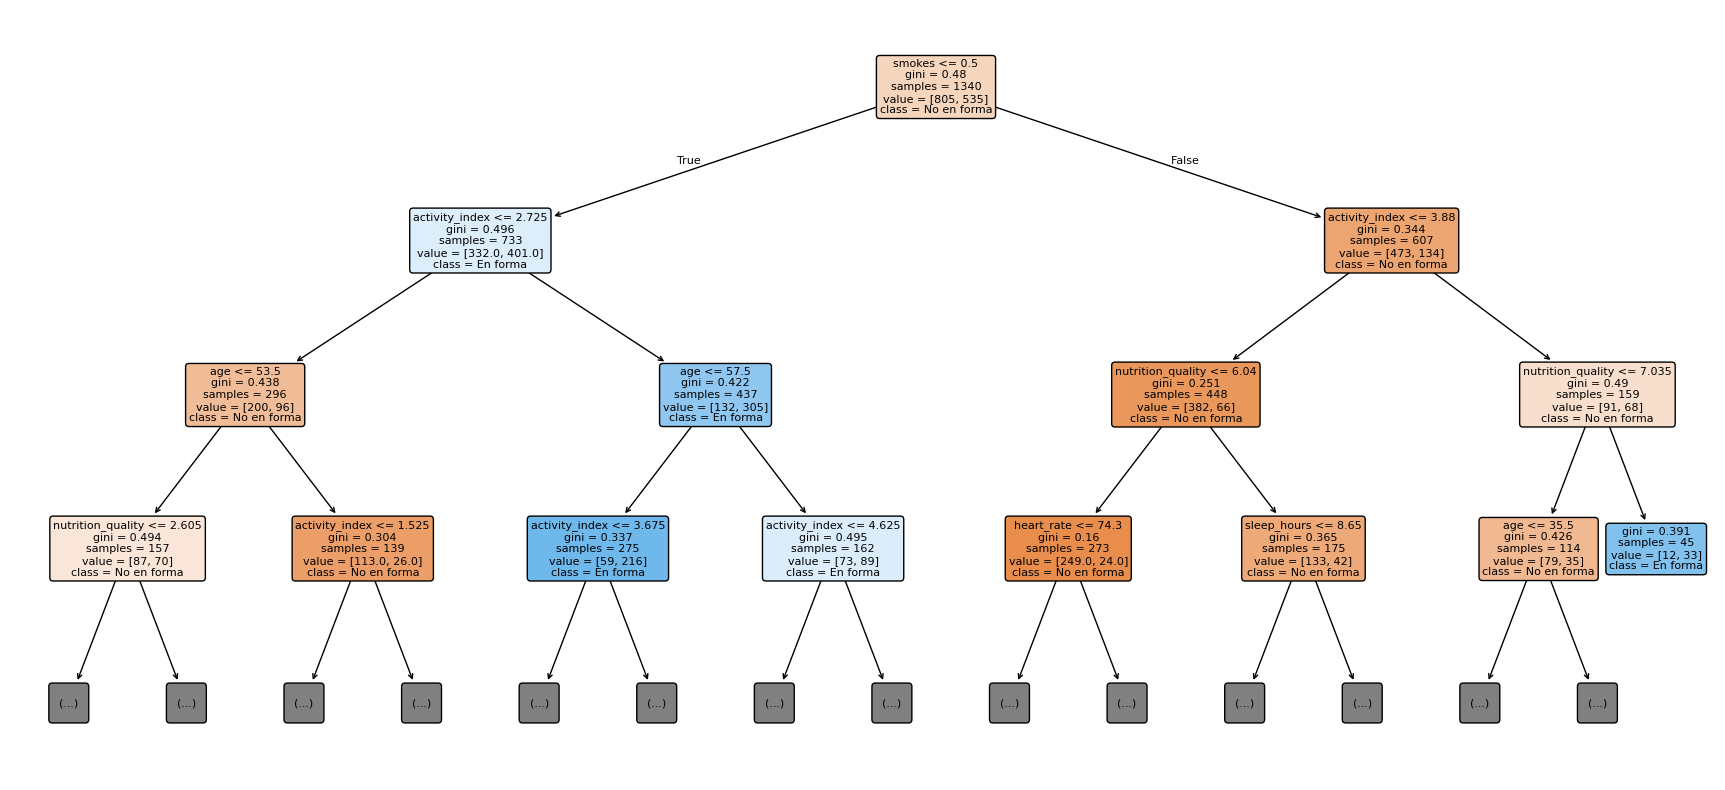

In [26]:
from sklearn.tree import plot_tree

features = list(X)
target = ['No en forma', 'En forma']

plt.figure(figsize=(22, 10))
plot_tree(dtree, feature_names=features, class_names=target, filled=True, rounded=True, max_depth=3, fontsize=8)
plt.show()   # se muestran sólo los primeros 3 niveles para que sea legible

In [27]:
from sklearn.inspection import permutation_importance

atributos = permutation_importance(dtree, X_train, y_train, n_repeats=30, random_state=0)
per_dt = pd.DataFrame({'Atributo': X_train.columns,
                       'Importancia': atributos.importances_mean,
                       'Desviación std': atributos.importances_std})
per_dt.sort_values('Importancia', ascending=False)

,Atributo,Importancia,Desviación std
7,activity_index,0.123881,0.009728
8,smokes,0.081244,0.007514
0,age,0.055821,0.005179
6,nutrition_quality,0.055075,0.006236
5,sleep_hours,0.016343,0.004966
3,heart_rate,0.012239,0.003401
1,height_cm,0.000000,0.000000
2,weight_kg,0.000000,0.000000
4,blood_pressure,0.000000,0.000000
9,gender,0.000000,0.000000


# Predicción para un registro en particular

In [28]:
test = pd.DataFrame({'age': [30], 'height_cm': [175], 'weight_kg': [70], 'heart_rate': [60.0],
                     'blood_pressure': [115.0], 'sleep_hours': [8.0], 'nutrition_quality': [8.0],
                     'activity_index': [4.0], 'smokes': [0], 'gender': [1]})

test_dt = dtree.predict(test)
print("Predicción:", 'En forma' if test_dt[0] == 1 else 'No en forma')
print("Probabilidades [No en forma, En forma]:", dtree.predict_proba(test)[0].round(2))

Predicción: En forma
Probabilidades [No en forma, En forma]: [0.03 0.97]
